# CA1 – Categorical Features
Cillian Murphy - X00226829

# 1. Loading Dataset

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from plotnine import *
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

bankData = pd.read_csv("bank-additional-full.csv", sep=";")


print(bankData.shape)
bankData.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# 2. Exploratory Data Analysis

In [ ]:
# Separating into only string (obj) features

strFeatures = bankData.drop(columns="y").select_dtypes(include="object").columns.tolist() # selects all features to a list (excluding y)
bankData.info()
bankData[strFeatures].head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent


Job, contact, month, day_of_week, marital and poutcome are all nominal features as, for example a persons job type has no inherent hierarchy; default, housing and loan are also nominal but are binary features (yes or no).

Education is a ordinal feature as education level does have a hierarchy.

## 2.1 Summary Statistics

In [ ]:
bankData.select_dtypes(include="object").describe()


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


All features have 41,188 values so there are no empty values however there still could be other versions of missing values such as "unknown", "N/A" etc which is confirmed since default, housing and loan (which are all yes or no values) have 3 unique values. There are 12 different jobs listed in this dataset.
The modes are also displayed here in the "top" row, the mode of poutcome  is "nonexistent" which may seem like a missing value but is not.

In [ ]:
bankData.select_dtypes(include="object").nunique()


,0
job,12
marital,4
education,8
default,3
housing,3
loan,3
contact,2
month,10
day_of_week,5
poutcome,3


In [ ]:
bankData.duplicated().sum()

np.int64(12)

There are 12 duplicate rows

## 2.2 Count Histrograms
Histograms for the count and percentage of each categorical feature



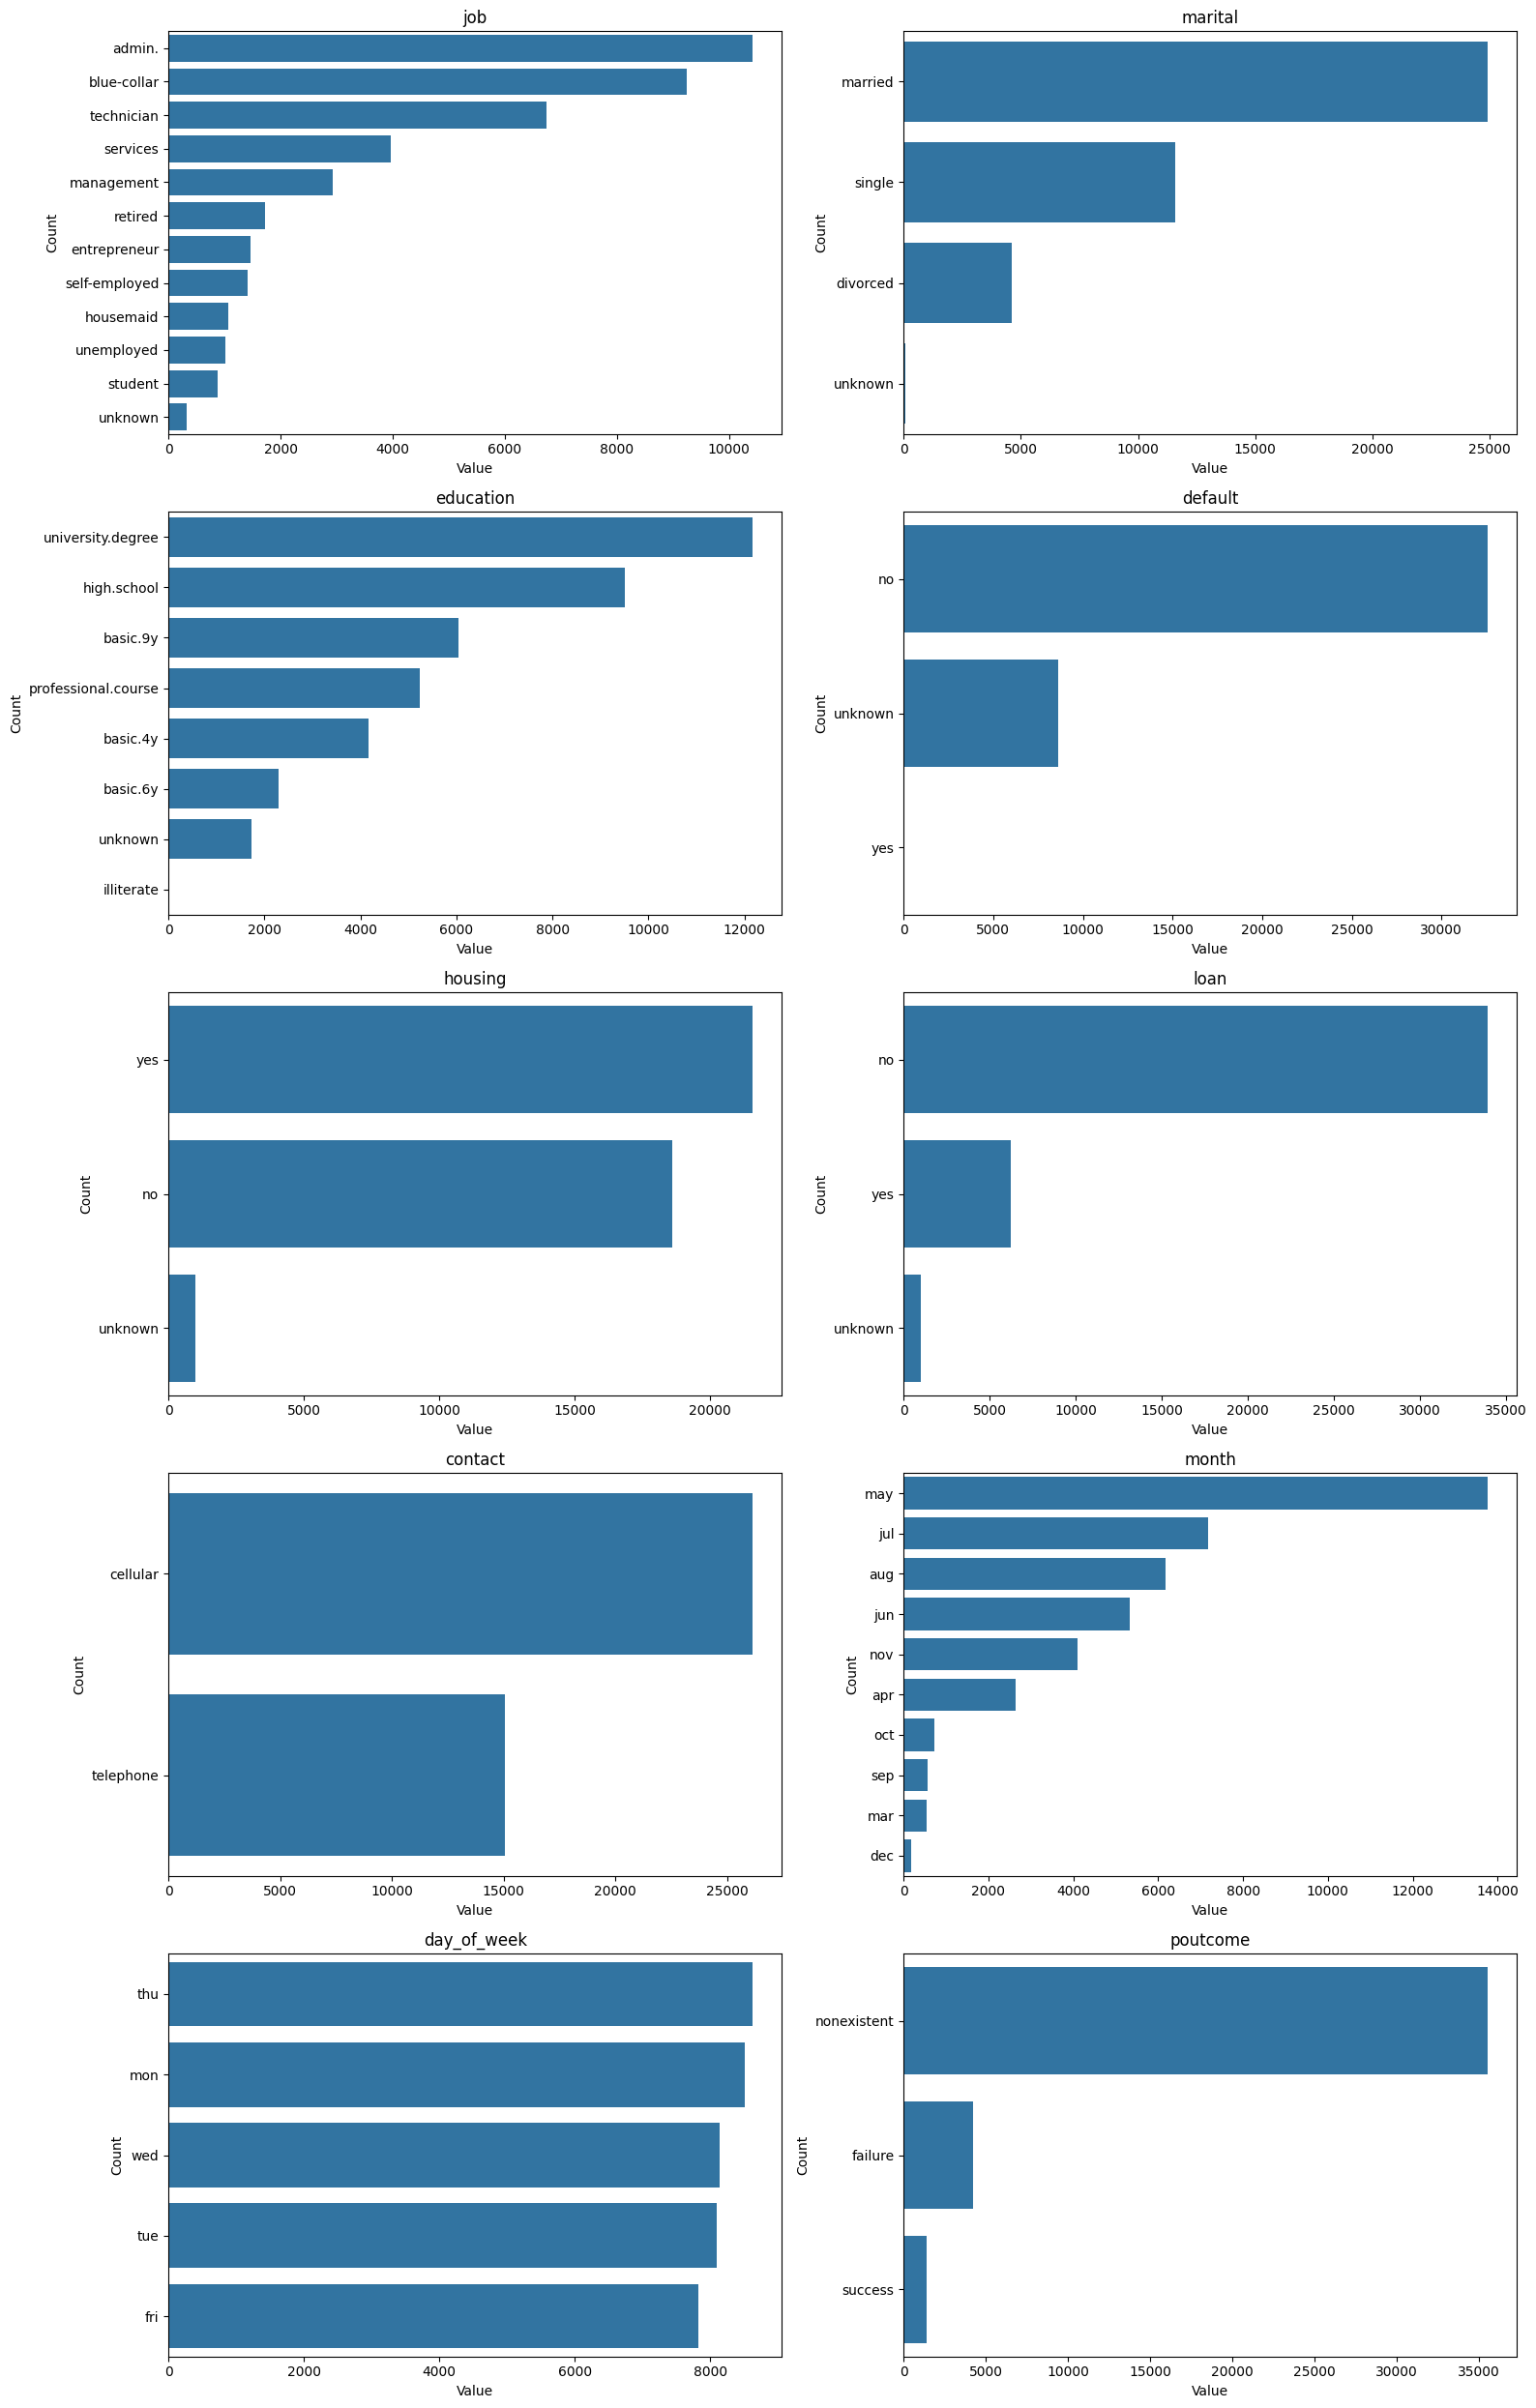

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for i, col in enumerate(bankData[strFeatures]):
  # get percentage instead of count
  counts = (bankData[col].value_counts()).reset_index()
  counts.columns = ['Value', 'Count']

  sns.barplot(data=counts, x="Count", y="Value", ax=axes[i])
  #change figsize with rc instead of plt
  axes[i].set_title(col)
  axes[i].set_xlabel('Value')
  axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()


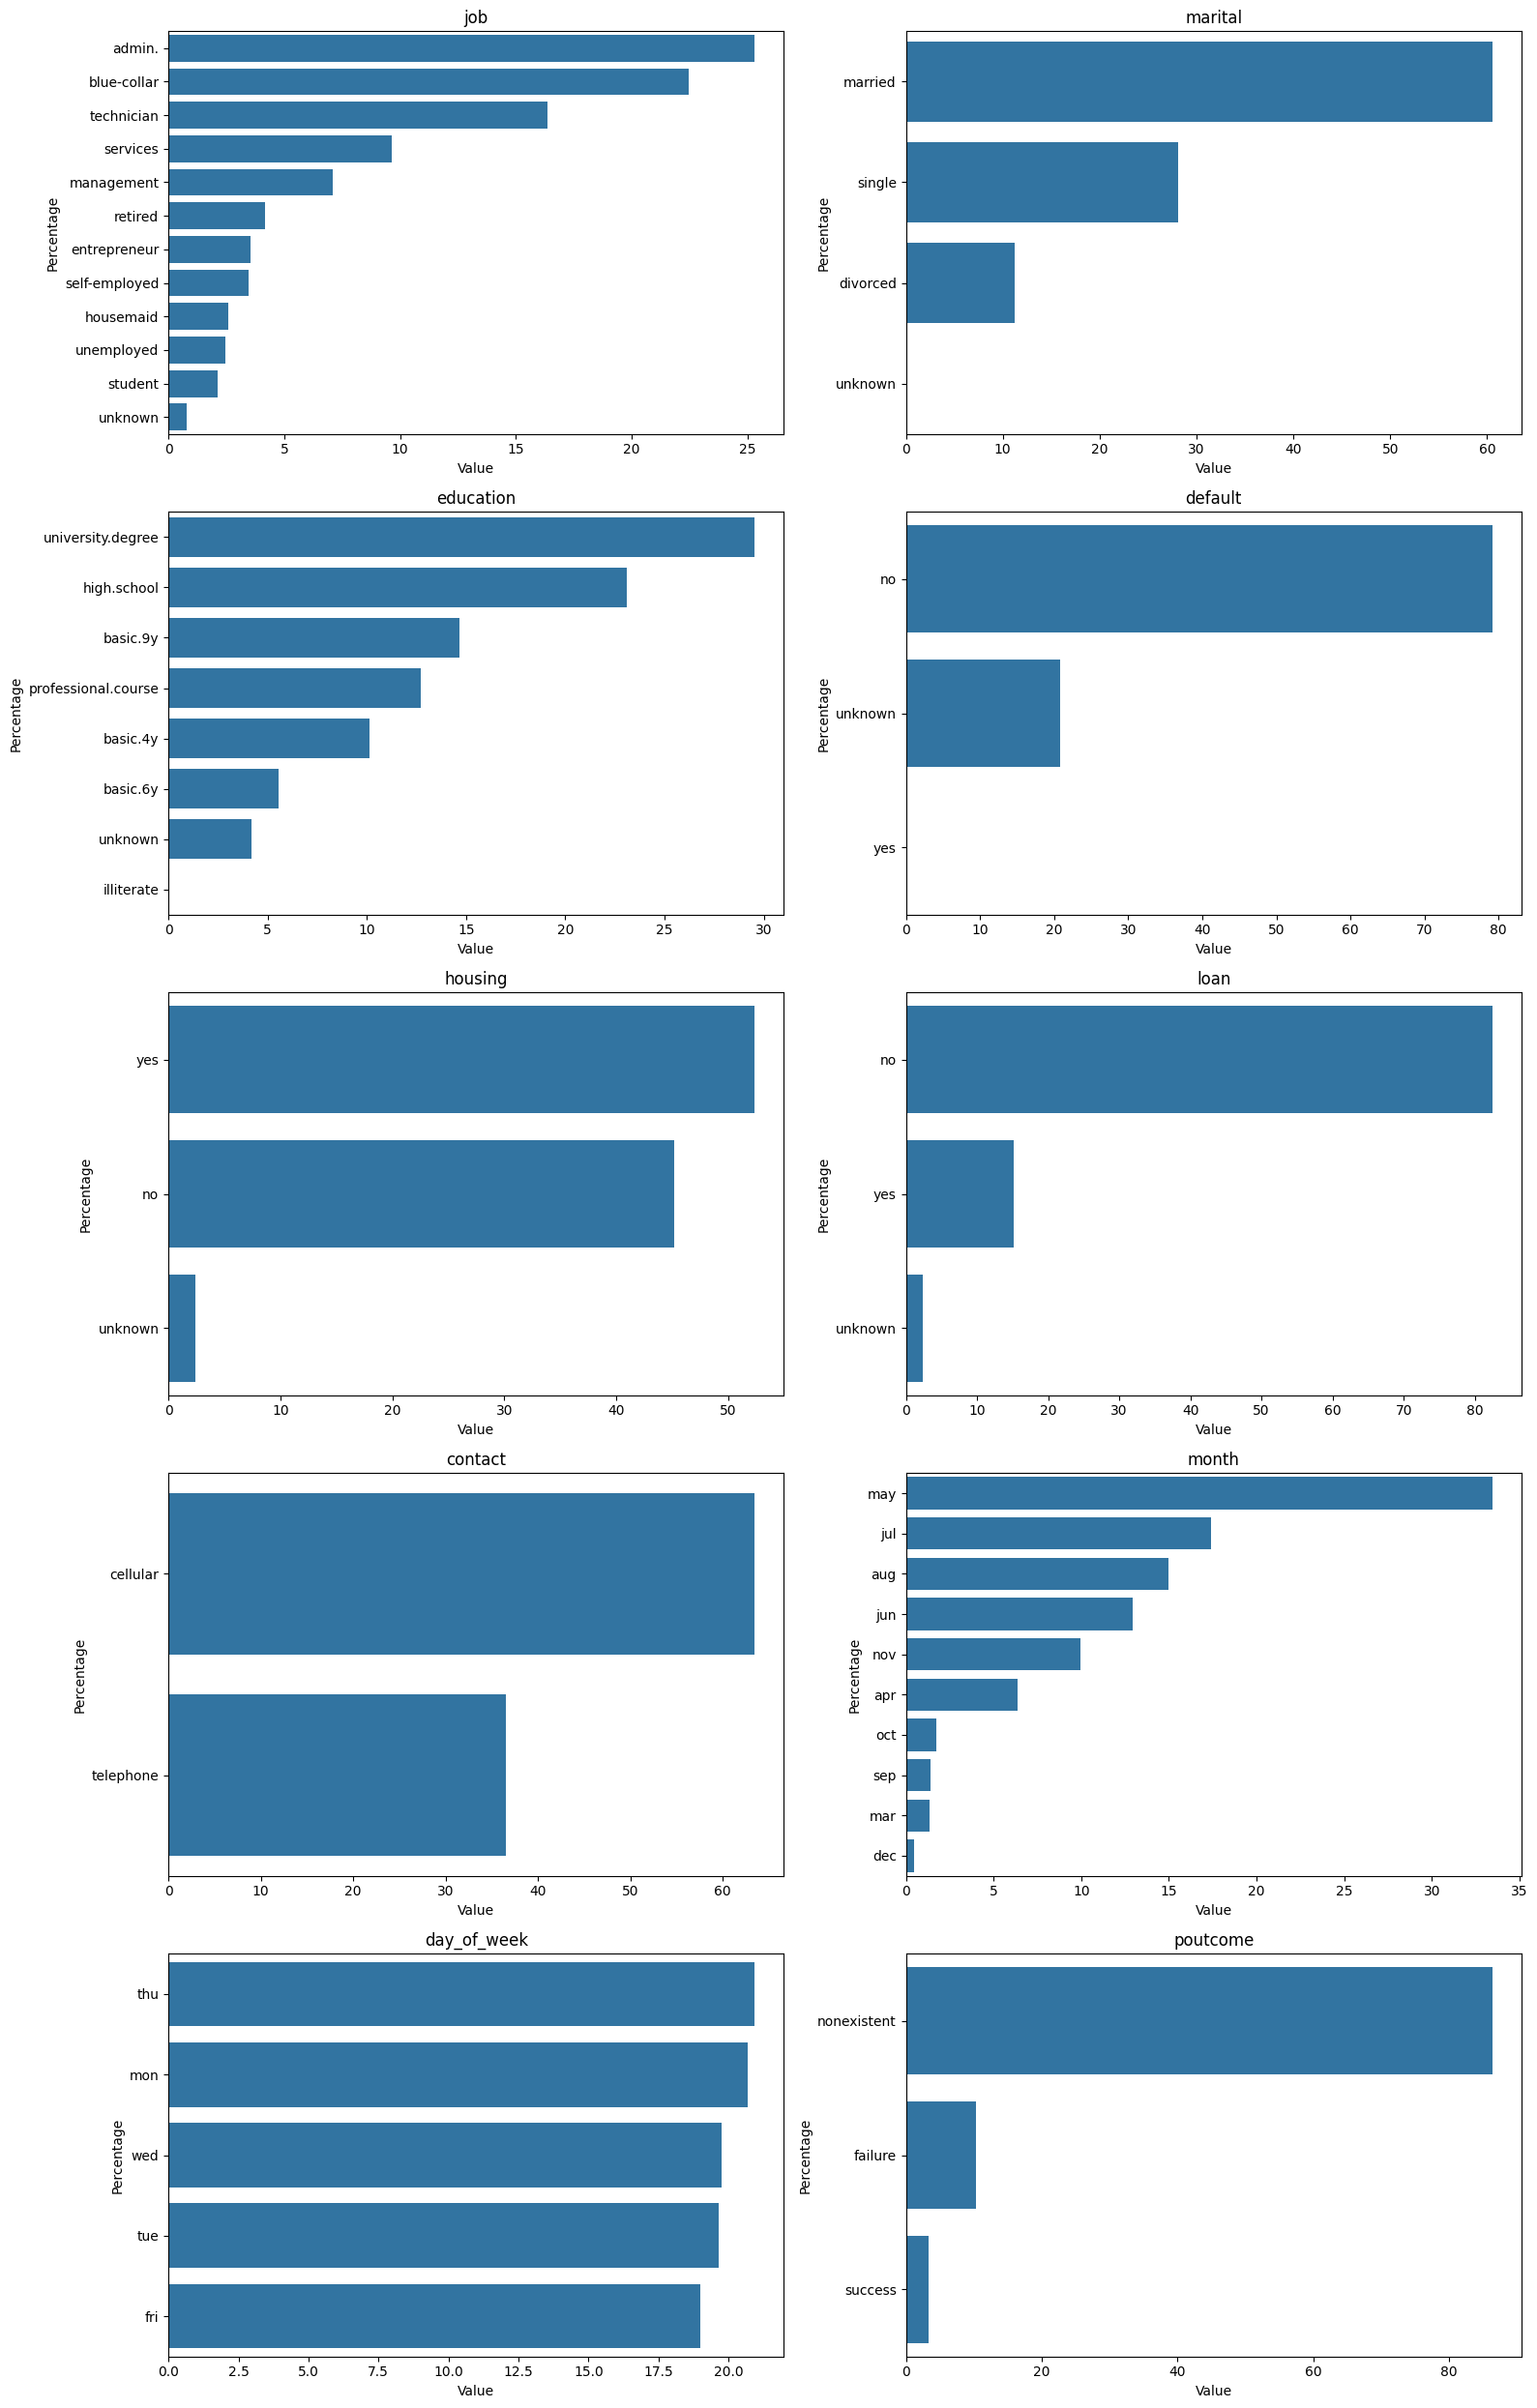

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for i, col in enumerate(bankData[strFeatures]):
  # get percentage instead of count
  counts = (bankData[col].value_counts(normalize=True)* 100).reset_index()
  counts.columns = ['Value', 'Percentage']

  sns.barplot(data=counts, x="Percentage", y="Value", ax=axes[i])
  #change figsize with rc instead of plt
  axes[i].set_title(col)
  axes[i].set_xlabel('Value')
  axes[i].set_ylabel('Percentage')

plt.tight_layout()
plt.show()

Most of these features are fairly normal however most values for poutcome are heavily imbalanced with it mostly being "nonexistent", some features have a few "unknown" values though this will be looked into further with the missingness summary, loan is also an imbalanced feature.

## 2.3 Missingness Summary

In [ ]:
unknownCount = (bankData.select_dtypes(include="object") == 'unknown').sum()
unknownPercent = (bankData.select_dtypes(include="object") == 'unknown').mean()

print(unknownCount)

job             330
marital          80
education      1731
default        8597
housing         990
loan            990
contact           0
month             0
day_of_week       0
poutcome          0
y                 0
dtype: int64


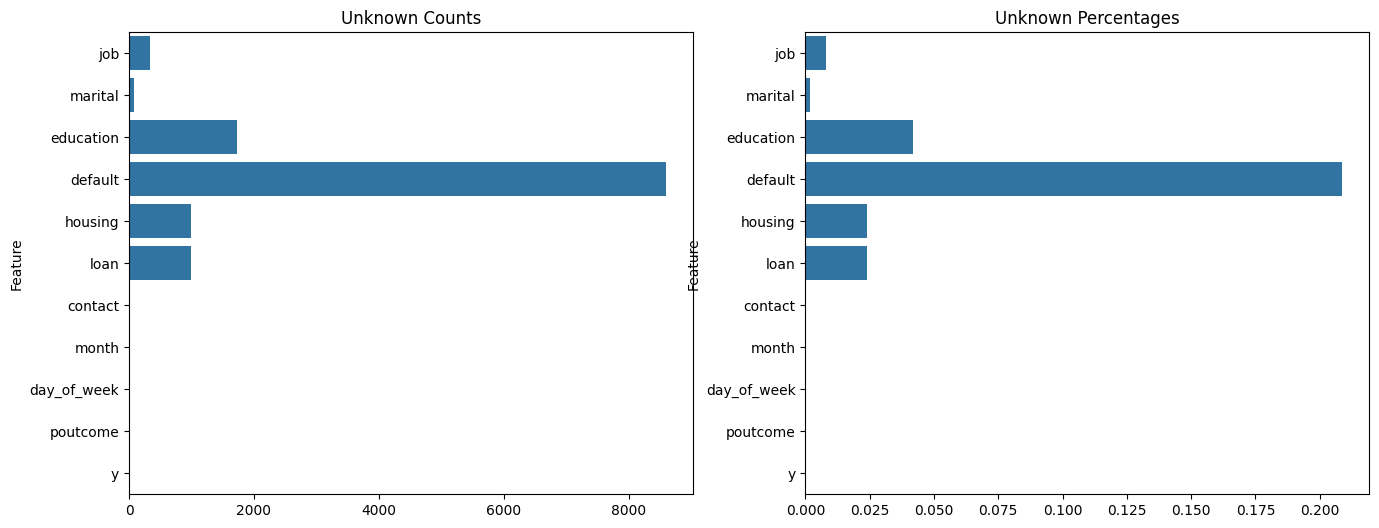

In [ ]:
unknownCount = (bankData.select_dtypes(include="object") == 'unknown').sum()
unknownPercent = (bankData.select_dtypes(include="object") == 'unknown').mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

counts = sns.barplot(x=unknownCount.values, y=unknownCount.index , ax=axes[0])
counts.set_ylabel("Feature")
counts.set_title("Unknown Counts")


percents = sns.barplot(x=unknownPercent.values, y=unknownPercent.index, ax=axes[1])
percents.set_ylabel("Feature")
percents.set_title("Unknown Percentages")
plt.show()


In [ ]:
print("\nNull Values")
bankData.select_dtypes(include="object").isnull().mean()*100


Null Values


,0
job,0.0
marital,0.0
education,0.0
default,0.0
housing,0.0
loan,0.0
contact,0.0
month,0.0
day_of_week,0.0
poutcome,0.0


default has the highest unknow rate, with over 20% of its rows being unknown. Contant, month, day_of_week, poutcome and the target feature have no uknowns.
No categorical feature has a fully missing/null values, as seen that every mean for isnull is 0.
Housing and loan have an equal number of 'unknown' rows so it may be suitable to keep unknown as its own value since it could be informative.

## 2.4 Target Balance

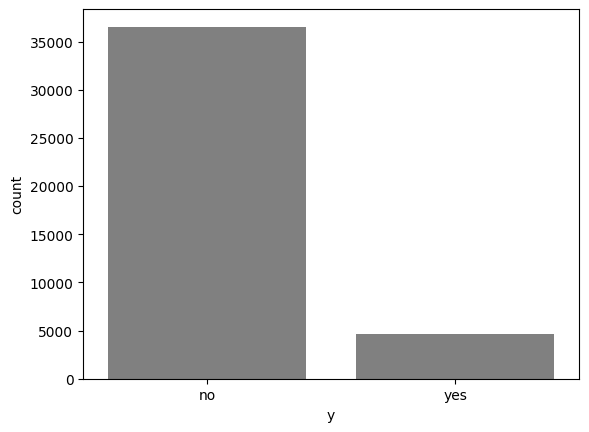

In [ ]:
targetPercentage = bankData["y"].value_counts(normalize=True) , sns.countplot(x="y", color="gray", data=bankData)

Targets are imbalanced with around 88.7% no and 11.3% yes so a vast majority of rows are no.

## 2.5 Target Rate Per Feature

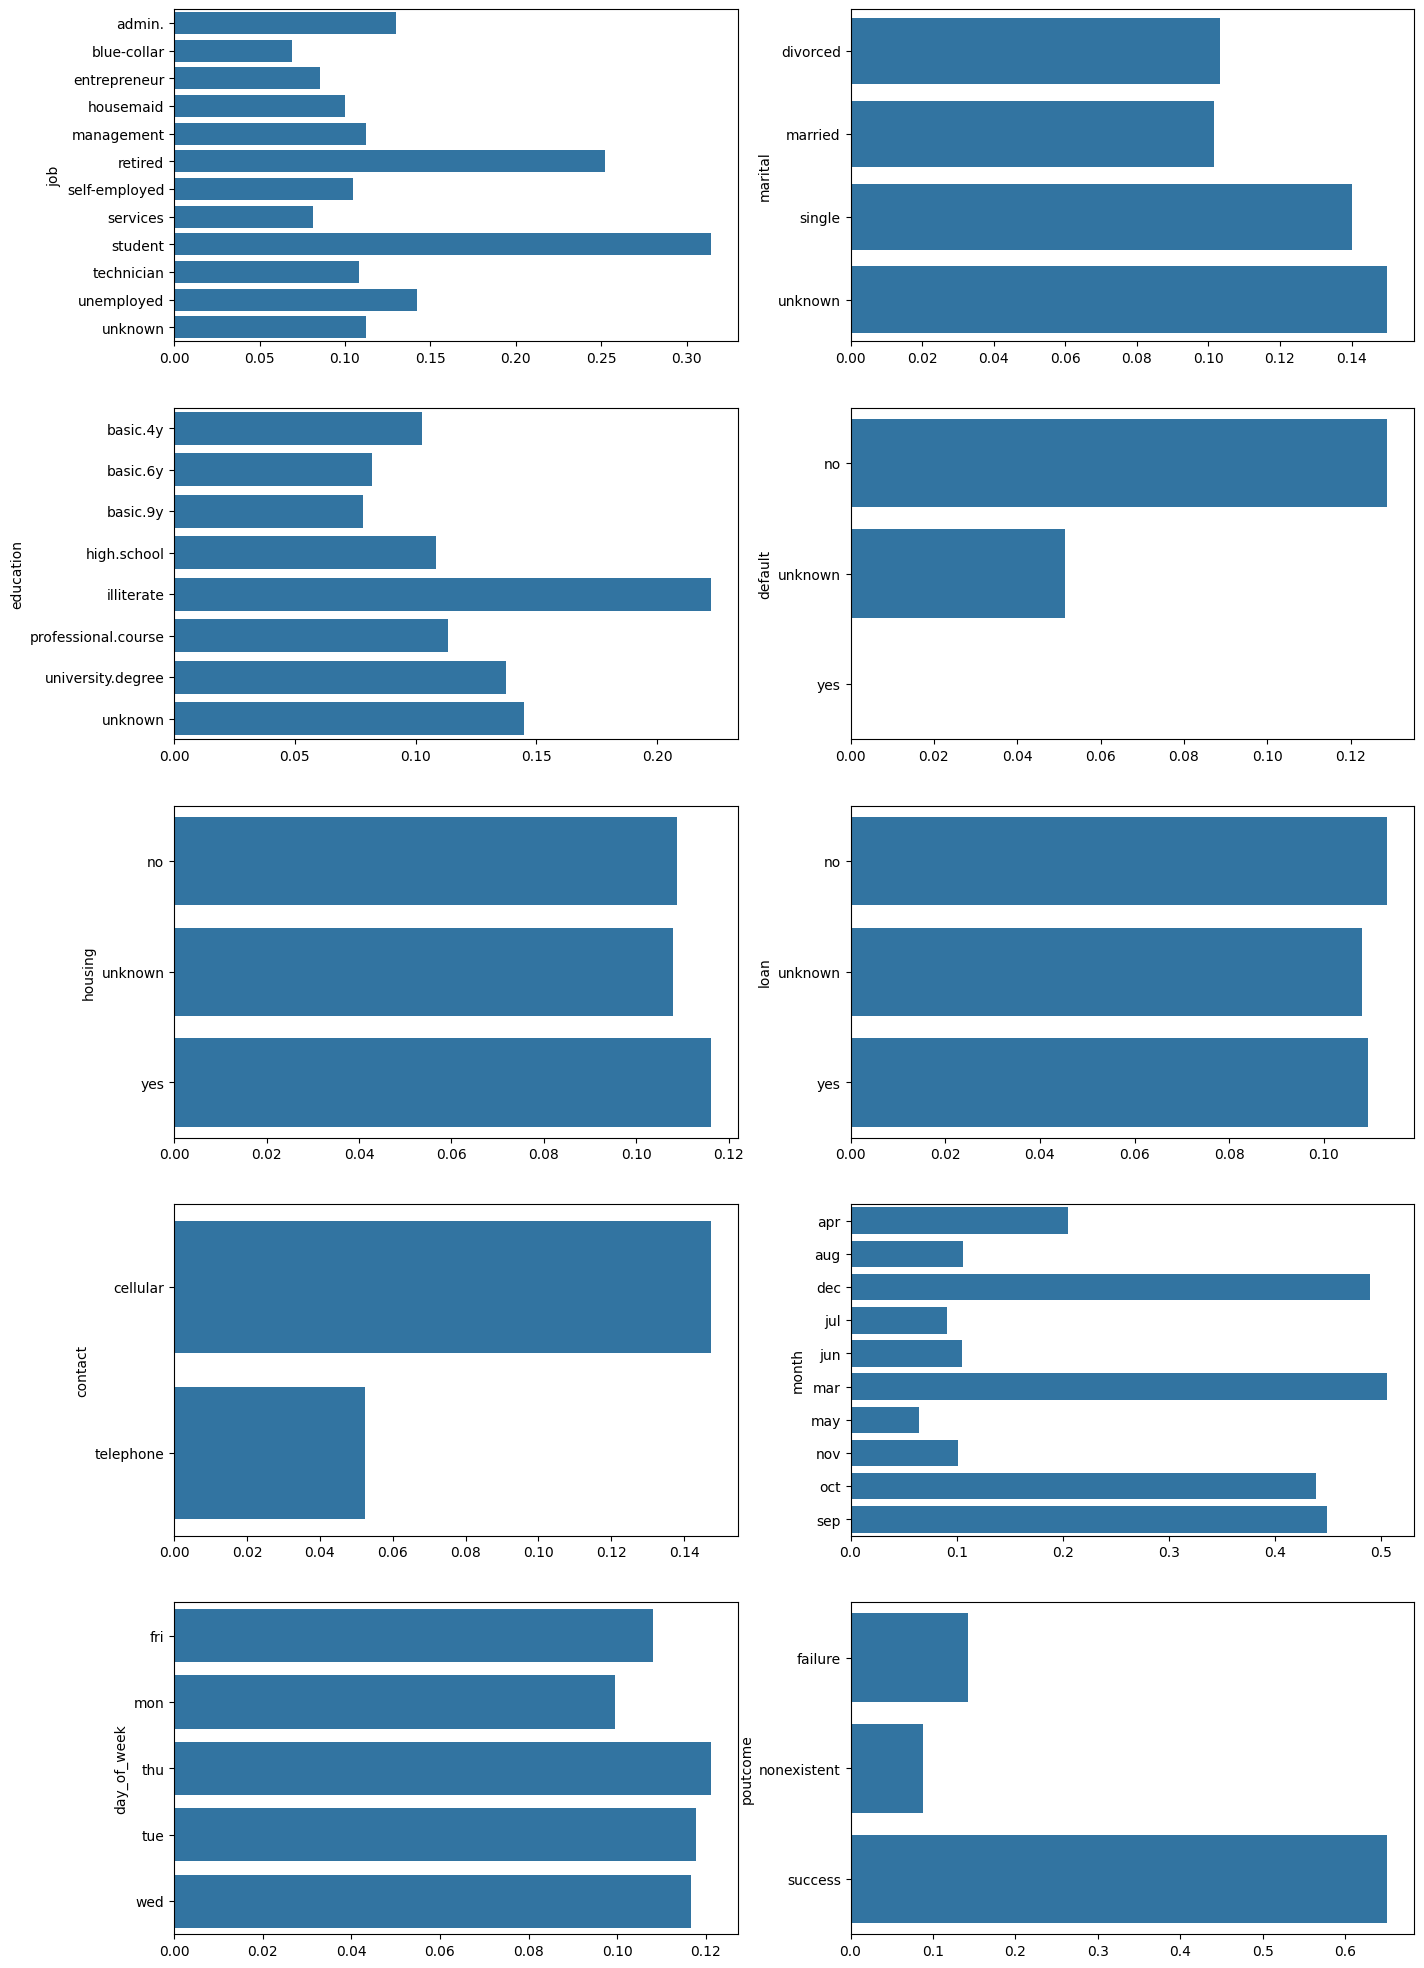

In [ ]:
bankDataCopy = bankData.copy()
bankDataCopy["yes"] = (bankData['y']=='yes')
fig, axes = plt.subplots(5, 2, figsize=(16, 5 * 5))
axes = axes.flatten()


for i, col in enumerate(strFeatures):
  rate = bankDataCopy.groupby(col)['yes'].mean()
  sns.barplot(x=rate.values, y=rate.index, ax=axes[i])
for j in range(len(strFeatures), len(axes)):
    fig.delaxes(axes[j])

plt.show()

Student has the highest yes rate for jobs with over 30% of, highest yes rate for marital is an missing value ("unknown"), illiterate has the highest yes rate for education with over 20%, a default of no has the highest yes rate, so more likely to be yes if the customer does not have overdue loan, if the previous marketing campaign is a success for this person the yes rate is higher
Of course the yes rate for the actualy target column yes is 100%, this is just a control plot to see that the values are correct.

# 3 Data Preprocessing

## 3.1 Data Quality

In [ ]:
bankData.drop(columns="y").select_dtypes(include="object").nunique()

,0
job,12
marital,4
education,8
default,3
housing,3
loan,3
contact,2
month,10
day_of_week,5
poutcome,3


No high cardinality featues, highest is job with only 12 unique values.

In [ ]:
print(bankData["default"].value_counts(dropna=False, normalize=True))

default
no         0.791201
unknown    0.208726
yes        0.000073
Name: proportion, dtype: float64


As seen in the previous graphs default is near-constant with no being 79% of the values, this would be even higher after the test/train split so it may not be a feature worth keeping.

## 3.2 Missing Data and Leakage Removal / split


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


bankData = bankData.loc[:,~bankData.columns.duplicated()].copy()
# for encoding target
le = LabelEncoder()

# Set which columns unknown values are being kept
keepCols = ['housing', 'loan']
replaceCols = bankData.columns.difference(keepCols)

# X = the information about clients, y = the answer (yes/no)
X = bankData.drop(columns=["y", "duration"])

# Set which columns unknown values are being kept
keepCols = ['housing', 'loan']
replaceCols = X.columns.difference(keepCols)
# Replace unknown with NaN for pipeline (apart from housing and loan)
X[replaceCols] = X[replaceCols].replace('unknown', np.nan)
y = le.fit_transform(bankData["y"])

# cut into 80% train and 20% test, same yes/no mix in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (32950, 19)  Test: (8238, 19)


## 3.3 Pipeline

In [ ]:
from sklearn import preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder



ordinalCols = ['education']
binaryCols  = ['housing', 'loan', 'contact']
nominalCols = ['job', 'marital', 'poutcome', 'month', 'day_of_week']

# Order of values for ordinal encoding (aka 0,1,2,3 etc)
eduLevelOrder = ['illiterate', 'basic.4y', 'basic.6y', 'basic.9y',
             'high.school', 'professional.course', 'university.degree']

#Creating Pipeline
encImpPreprocessor = ColumnTransformer([
    # ordinal: explicit order, unknown (NaN) imputed with mode
    ('ord', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OrdinalEncoder(categories=[eduLevelOrder]))
    ]), ordinalCols),

    # binary: impute then one-hot with drop='if_binary' to a single 0/1 column
    ('bin', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
    ]), binaryCols),

    # nominal: impute then one-hot
    ('nom', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OneHotEncoder(drop='first', handle_unknown='ignore'))
    ]), nominalCols)
])

encImpPreprocessor.fit_transform(X_train)

# get feature names after encoding
strProcessedNames = encImpPreprocessor.get_feature_names_out()

print(strProcessedNames)

['ord__education' 'bin__housing_no' 'bin__housing_unknown'
 'bin__housing_yes' 'bin__loan_no' 'bin__loan_unknown' 'bin__loan_yes'
 'bin__contact_telephone' 'nom__job_blue-collar' 'nom__job_entrepreneur'
 'nom__job_housemaid' 'nom__job_management' 'nom__job_retired'
 'nom__job_self-employed' 'nom__job_services' 'nom__job_student'
 'nom__job_technician' 'nom__job_unemployed' 'nom__marital_married'
 'nom__marital_single' 'nom__poutcome_nonexistent' 'nom__poutcome_success'
 'nom__month_aug' 'nom__month_dec' 'nom__month_jul' 'nom__month_jun'
 'nom__month_mar' 'nom__month_may' 'nom__month_nov' 'nom__month_oct'
 'nom__month_sep' 'nom__day_of_week_mon' 'nom__day_of_week_thu'
 'nom__day_of_week_tue' 'nom__day_of_week_wed']


## 4 Feature Selection

## 4.1 Chi Squared

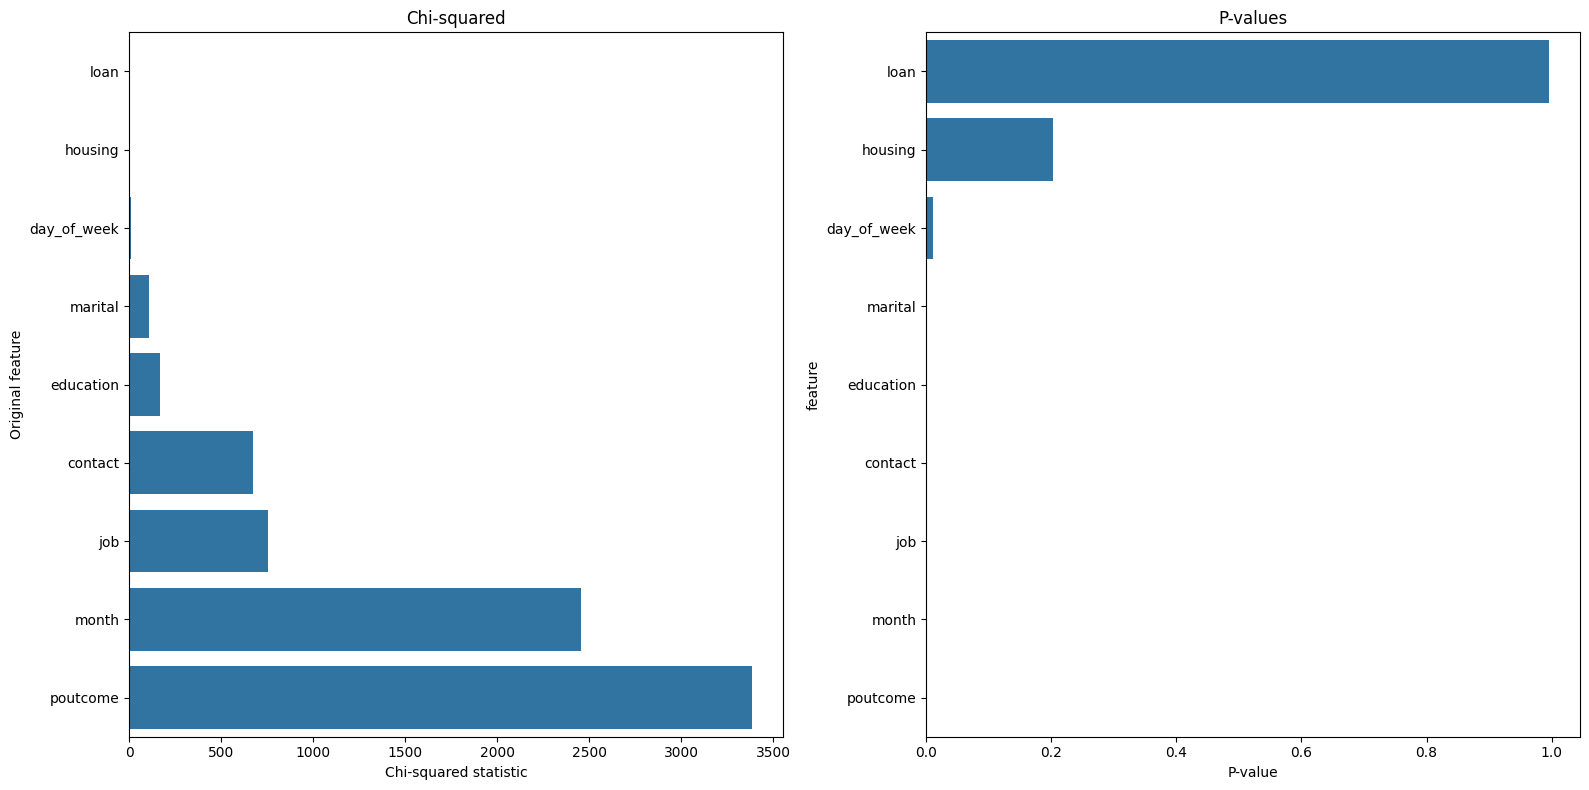

In [ ]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

# use original feature names
x_original = X_train.reset_index(drop=True).copy()
y_original = pd.Series(y_train).reset_index(drop=True)

groupedResults = []

for feature in ordinalCols + binaryCols + nominalCols:
    # Treat missing values as a category for this test
    xValues = x_original[feature].astype(str)

    # need a table for chi squared if values arent encoded
    chiTable = pd.crosstab(xValues, y_original)

    chi_val, p_val, dof, expectedFreq = chi2_contingency(chiTable)

    groupedResults.append({
        'feature': feature,
        'chi2': chi_val,
        'p': p_val,
    })

chiDf = pd.DataFrame(groupedResults)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

plotChi = chiDf.sort_values('chi2', ascending=True)

sns.barplot(data=plotChi, x='chi2', y='feature', ax=axes[0])
axes[0].set_title('Chi-squared')
axes[0].set_xlabel('Chi-squared statistic')
axes[0].set_ylabel('Original feature')

sns.barplot(data=plotChi, x='p', y='feature', ax=axes[1])
axes[1].set_title('P-values')
axes[1].set_xlabel('P-value')
axes[1].set_ylabel('feature')

plt.tight_layout()
plt.show()





## 4.2 Mutual Information

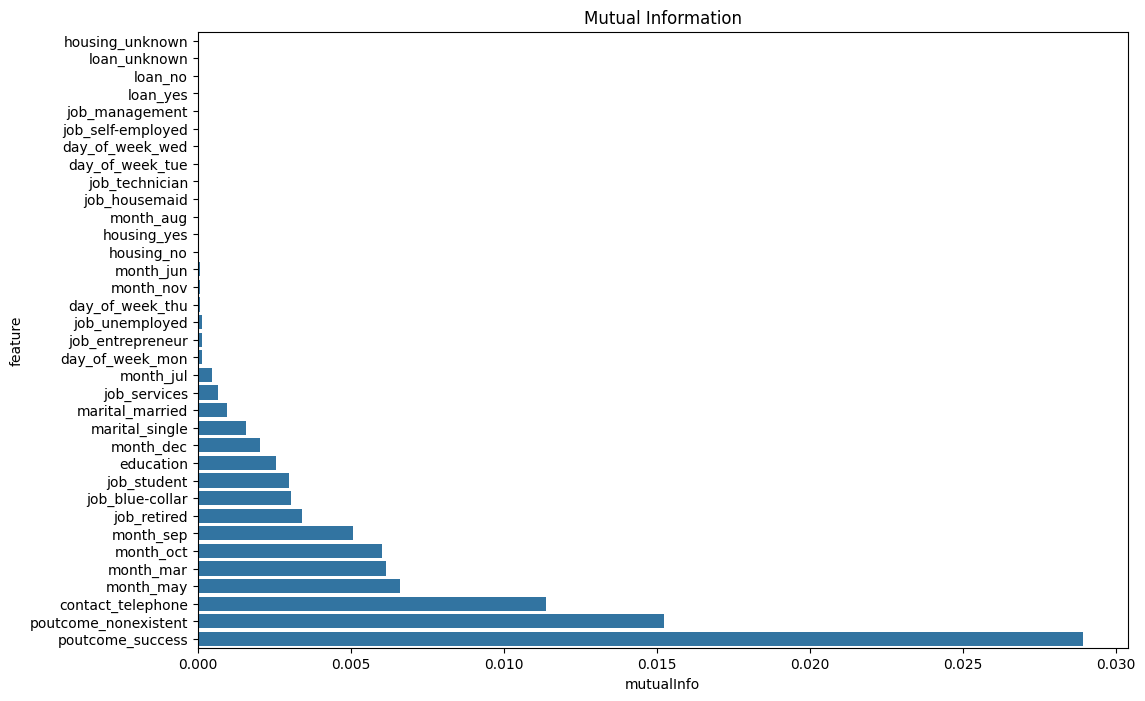

In [ ]:
from sklearn.feature_selection import mutual_info_classif

miVals = mutual_info_classif(xProcessed, y_train, discrete_features=True)

miDf = pd.DataFrame({'feature': strFeatureNames, 'mutualInfo': miVals}).sort_values('mutualInfo')

plt.figure(figsize=(12,8))
miPlot = sns.barplot(data=miDf, x='mutualInfo', y='feature')
plt.title("Mutual Information")
plt.show()

## 4.3 Backward Elimination


In [ ]:
import statsmodels.api as sm

ySelection = pd.Series(y_train).reset_index(drop=True)
xSelection = pd.DataFrame(
    xProcessed.toarray() if hasattr(xProcessed, "toarray")
    else xProcessed,
    columns=featureNames
).reset_index(drop=True)


model = sm.Logit(ySelection, xSelection).fit(disp=0)


p_values = model.pvalues.drop('const', errors='ignore')

results = pd.DataFrame({
    'Feature': p_values.index,
    'P-value': p_values.values,
    'Significant': p_values.values < 0.05
}).sort_values('P-value')

print(results)


                      Feature        P-value  Significant
21      nom__poutcome_success  8.365402e-149         True
7      bin__contact_telephone   1.904699e-64         True
27             nom__month_may   1.300652e-28         True
22             nom__month_aug   5.548018e-27         True
28             nom__month_nov   6.541098e-24         True
24             nom__month_jul   7.374743e-24         True
26             nom__month_mar   1.852308e-22         True
12           nom__job_retired   1.304360e-14         True
29             nom__month_oct   1.368453e-13         True
15           nom__job_student   2.665213e-07         True
30             nom__month_sep   1.775224e-06         True
23             nom__month_dec   2.814654e-06         True
8        nom__job_blue-collar   3.575562e-05         True
14          nom__job_services   5.868085e-04         True
19        nom__marital_single   9.031529e-04         True
0              ord__education   6.309954e-03         True
31       nom__

## 4.4 Gini Importance

                      Feature  Gini Importance
0              ord__education         0.159080
21      nom__poutcome_success         0.108740
20  nom__poutcome_nonexistent         0.047042
33       nom__day_of_week_tue         0.038630
32       nom__day_of_week_thu         0.037848
7      bin__contact_telephone         0.037662
34       nom__day_of_week_wed         0.035987
31       nom__day_of_week_mon         0.035412
18       nom__marital_married         0.029628
16        nom__job_technician         0.029471
25             nom__month_jun         0.025137
26             nom__month_mar         0.024671
1             bin__housing_no         0.024640
3            bin__housing_yes         0.024416
29             nom__month_oct         0.023886
22             nom__month_aug         0.023784
27             nom__month_may         0.023732
24             nom__month_jul         0.022297
19        nom__marital_single         0.021975
28             nom__month_nov         0.021147
11        nom

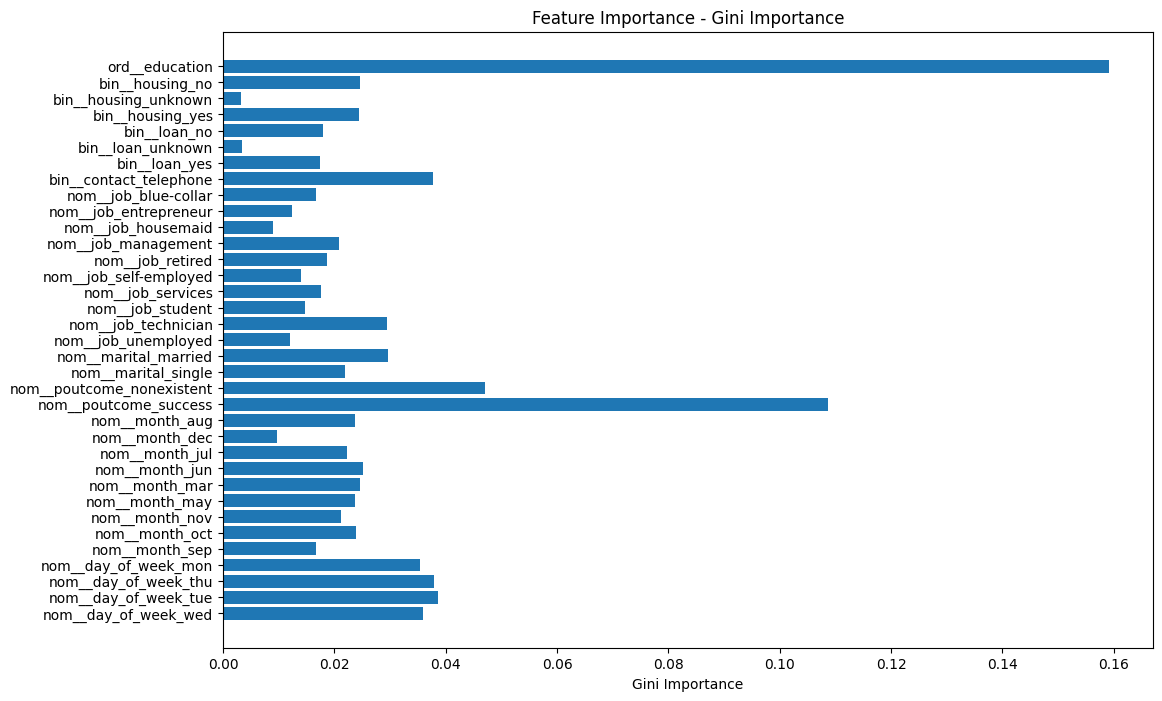

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(xProcessed, y_train)

importances = clf.feature_importances_
featureImpDf = pd.DataFrame({'Feature': strProcessedNames, 'Gini Importance': importances}).sort_values(
    'Gini Importance', ascending=False)
print(featureImpDf)

plt.figure(figsize=(12, 8))
plt.barh(strProcessedNames, importances)
plt.xlabel('Gini Importance')
plt.title('Feature Importance - Gini Importance')
plt.gca().invert_yaxis()
plt.show()